In [ ]:
#!/usr/bin/env python3
"""
Summarize spearman coefficients by task and pipeline.
Creates text files ranking pipelines for each task, plus an overall ranking.
"""

import pandas as pd
import os
from pathlib import Path
import numpy as np

# Base directory containing all spearman outputs
BASE_DIR = "/path/to/project/group_levels/spearman_masked"
OUTPUT_DIR = "/path/to/project/group_levels/spearman_summaries_masked"

# Create output directory
os.makedirs(OUTPUT_DIR, exist_ok=True)

# All tasks and pipelines
TASKS = ["nback", "gonogo", "mid", "oasis"]
PIPELINES = [
    "6HMP", "24HMP", "6HMP_aCompCor", "6HMP_spike_reg", 
    "24HMP_aCompCor", "6HMP_WM_CSF", "24HMP_WM_CSF", "24HMP_spike_reg",
    "6HMP_aCompCor_spike_reg", "24HMP_aCompCor_spike_reg", 
    "6HMP_WM_CSF_spike_reg", "24HMP_WM_CSF_spike_reg"
]

def read_spearman_value(filepath):
    """Read spearman coefficient from text file, return float or None for NA/missing."""
    try:
        with open(filepath, 'r') as f:
            value = f.read().strip()
            
            # Empty file
            if value == "":
                return None
            
            # Check if it starts with "spearman: " and remove it
            if value.startswith("Spearman_r: "):
                value = value.replace("Spearman_r: ", "").strip()
            
            # Explicit NA
            if value.upper() == "NA":
                return None
            
            # Try to parse as float (handles both .514567 and 0.514567)
            try:
                float_val = float(value)
                return float_val
            except ValueError:
                return None
                
    except FileNotFoundError:
        return None
    except Exception:
        return None

def collect_all_spearman_data():
    """Collect all spearman coefficients into a DataFrame."""
    data = []
    
    for task in TASKS:
        task_dir = Path(BASE_DIR) / task
        if not task_dir.exists():
            print(f"Warning: {task_dir} does not exist")
            continue
            
        for pipeline in PIPELINES:
            pipeline_dir = task_dir / pipeline
            if not pipeline_dir.exists():
                continue
                
            # Find all cope directories
            for cope_dir in pipeline_dir.glob("cope*"):
                cope = cope_dir.name
                
                spearman_file = cope_dir / f"{task}_{cope}_{pipeline}_spearman.txt"
                if not spearman_file.exists():
                    spearman_file = cope_dir / "spearman_result.txt"
                
                if spearman_file.exists():
                    spearman_value = read_spearman_value(spearman_file)
                    data.append({
                        "task": task,
                        "pipeline": pipeline,
                        "cope": cope,
                        "spearman": spearman_value,
                        "filepath": str(spearman_file)
                    })
    
    return pd.DataFrame(data)

def create_task_summary(df, task, output_file):
    """Create summary text file for a single task."""
    task_data = df[df["task"] == task].copy()
    
    if len(task_data) == 0:
        print(f"WARNING: No data found for task: {task}")
        with open(output_file, 'w') as f:
            f.write(f"No data found for task: {task}\n")
        return None
    
    # Calculate statistics per pipeline
    pipeline_stats = []
    for pipeline in PIPELINES:
        pipe_data = task_data[task_data["pipeline"] == pipeline]["spearman"]
        pipe_data_valid = pipe_data.dropna()
        
        if len(pipe_data_valid) > 0:
            pipeline_stats.append({
                "pipeline": pipeline,
                "mean_spearman": pipe_data_valid.mean(),
                "median_spearman": pipe_data_valid.median(),
                "std_spearman": pipe_data_valid.std(),
                "min_spearman": pipe_data_valid.min(),
                "max_spearman": pipe_data_valid.max(),
                "n_valid": len(pipe_data_valid),
                "n_na": len(pipe_data) - len(pipe_data_valid)
            })
    
    if len(pipeline_stats) == 0:
        print(f"WARNING: No valid pipeline data for task: {task}")
        with open(output_file, 'w') as f:
            f.write(f"No valid pipeline data found for task: {task}\n")
        return None
    
    stats_df = pd.DataFrame(pipeline_stats)
    stats_df = stats_df.sort_values("mean_spearman", ascending=False)
    
    # Write to text file
    with open(output_file, 'w') as f:
        f.write(f"=" * 80 + "\n")
        f.write(f"spearman COEFFICIENT SUMMARY FOR TASK: {task.upper()}\n")
        f.write(f"=" * 80 + "\n\n")
        
        f.write(f"Pipelines ranked by mean spearman coefficient (highest to lowest):\n")
        f.write(f"-" * 80 + "\n\n")
        
        for rank, (idx, row) in enumerate(stats_df.iterrows(), 1):
            f.write(f"Rank {rank}: {row['pipeline']}\n")
            f.write(f"  Mean spearman:   {row['mean_spearman']:.4f}\n")
            f.write(f"  Median spearman: {row['median_spearman']:.4f}\n")
            f.write(f"  Std Dev:     {row['std_spearman']:.4f}\n")
            f.write(f"  Min spearman:    {row['min_spearman']:.4f}\n")
            f.write(f"  Max spearman:    {row['max_spearman']:.4f}\n")
            f.write(f"  Valid copes: {row['n_valid']}\n")
            if row['n_na'] > 0:
                f.write(f"  NA values:   {row['n_na']}\n")
            f.write("\n")
        
        # Detailed breakdown by cope
        f.write(f"\n" + "=" * 80 + "\n")
        f.write(f"DETAILED BREAKDOWN BY COPE\n")
        f.write(f"=" * 80 + "\n\n")
        
        for pipeline in stats_df["pipeline"]:
            f.write(f"\n{pipeline}:\n")
            pipe_data = task_data[task_data["pipeline"] == pipeline].sort_values("cope")
            for _, row in pipe_data.iterrows():
                spearman_str = f"{row['spearman']:.4f}" if pd.notna(row['spearman']) else "NA"
                f.write(f"  {row['cope']}: {spearman_str}\n")
    
    print(f"Created summary for {task}: {output_file}")
    return stats_df

def create_overall_summary(df, output_file):
    """Create overall summary ranking all pipelines across all tasks."""
    
    if len(df) == 0:
        print("ERROR: No data to create overall summary!")
        return None
    
    # Calculate statistics per pipeline across ALL tasks
    pipeline_stats = []
    for pipeline in PIPELINES:
        pipe_data = df[df["pipeline"] == pipeline]["spearman"]
        pipe_data_valid = pipe_data.dropna()
        
        if len(pipe_data_valid) > 0:
            # Also calculate per-task means
            task_means = []
            for task in TASKS:
                task_pipe_data = df[(df["task"] == task) & (df["pipeline"] == pipeline)]["spearman"]
                task_pipe_valid = task_pipe_data.dropna()
                if len(task_pipe_valid) > 0:
                    task_means.append(task_pipe_valid.mean())
            
            pipeline_stats.append({
                "pipeline": pipeline,
                "overall_mean": pipe_data_valid.mean(),
                "overall_median": pipe_data_valid.median(),
                "overall_std": pipe_data_valid.std(),
                "min_spearman": pipe_data_valid.min(),
                "max_spearman": pipe_data_valid.max(),
                "n_total": len(pipe_data_valid),
                "n_na": len(pipe_data) - len(pipe_data_valid),
                "mean_of_task_means": np.mean(task_means) if task_means else None,
                "task_means": task_means
            })
    
    if len(pipeline_stats) == 0:
        print("ERROR: No valid pipeline statistics to create overall summary!")
        return None
    
    stats_df = pd.DataFrame(pipeline_stats)
    stats_df = stats_df.sort_values("overall_mean", ascending=False)
    
    # Write to text file
    with open(output_file, 'w') as f:
        f.write(f"=" * 80 + "\n")
        f.write(f"OVERALL spearman COEFFICIENT RANKING ACROSS ALL TASKS\n")
        f.write(f"=" * 80 + "\n\n")
        
        f.write(f"Pipelines ranked by overall mean spearman coefficient (highest to lowest):\n")
        f.write(f"-" * 80 + "\n\n")
        
        for rank, (idx, row) in enumerate(stats_df.iterrows(), 1):
            f.write(f"Rank {rank}: {row['pipeline']}\n")
            f.write(f"  Overall Mean spearman:   {row['overall_mean']:.4f}\n")
            f.write(f"  Overall Median spearman: {row['overall_median']:.4f}\n")
            f.write(f"  Overall Std Dev:     {row['overall_std']:.4f}\n")
            f.write(f"  Min spearman:            {row['min_spearman']:.4f}\n")
            f.write(f"  Max spearman:            {row['max_spearman']:.4f}\n")
            f.write(f"  Total valid copes:   {row['n_total']}\n")
            if row['n_na'] > 0:
                f.write(f"  NA values:           {row['n_na']}\n")
            
            # Show per-task performance
            f.write(f"  Per-task means:\n")
            for task_idx, task in enumerate(TASKS):
                if task_idx < len(row['task_means']):
                    f.write(f"    {task}: {row['task_means'][task_idx]:.4f}\n")
            f.write("\n")
        
        # Summary table
        f.write(f"\n" + "=" * 80 + "\n")
        f.write(f"SUMMARY TABLE\n")
        f.write(f"=" * 80 + "\n\n")
        f.write(f"{'Rank':<6} {'Pipeline':<30} {'Mean spearman':<12} {'Median spearman':<12}\n")
        f.write(f"-" * 80 + "\n")
        for rank, (idx, row) in enumerate(stats_df.iterrows(), 1):
            f.write(f"{rank:<6} {row['pipeline']:<30} {row['overall_mean']:<12.4f} {row['overall_median']:<12.4f}\n")
    
    print(f"Created overall summary: {output_file}")
    return stats_df

def main():
    print("=" * 80)
    print("spearman COEFFICIENT SUMMARIZATION")
    print("=" * 80)
    print()
    
    print("Collecting all spearman coefficient data...")
    df = collect_all_spearman_data()
    
    print(f"\nTotal entries found: {len(df)}")
    
    if len(df) == 0:
        print("ERROR: No data found! Check that BASE_DIR is correct:")
        print(f"  BASE_DIR = {BASE_DIR}")
        print("\nMake sure you have spearman coefficient files in this structure:")
        print("  BASE_DIR/task/pipeline/cope/spearman_coefficient.txt")
        return
    
    print(f"Valid spearman values: {df['spearman'].notna().sum()}")
    print(f"NA/missing values: {df['spearman'].isna().sum()}")
    
    # Show breakdown by task
    print("\nData found per task:")
    for task in TASKS:
        task_count = len(df[df["task"] == task])
        task_valid = df[(df["task"] == task) & (df["spearman"].notna())].shape[0]
        print(f"  {task}: {task_count} entries ({task_valid} valid spearman values)")
    
    # Create task-specific summaries
    print("\nCreating task-specific summaries...")
    task_stats = {}
    for task in TASKS:
        output_file = os.path.join(OUTPUT_DIR, f"spearman_summary_{task}.txt")
        task_stats[task] = create_task_summary(df, task, output_file)
    
    # Create overall summary
    print("\nCreating overall summary...")
    output_file = os.path.join(OUTPUT_DIR, "spearman_summary_overall.txt")
    overall_stats = create_overall_summary(df, output_file)
    
    if overall_stats is None:
        print("\nERROR: Could not create overall summary!")
        return
    
    # Also save as CSV for easy analysis
    print("\nSaving CSV files...")
    df.to_csv(os.path.join(OUTPUT_DIR, "all_spearman_values.csv"), index=False)
    overall_stats.to_csv(os.path.join(OUTPUT_DIR, "pipeline_rankings_overall.csv"), index=False)
    
    for task in TASKS:
        if task in task_stats and task_stats[task] is not None:
            task_stats[task].to_csv(
                os.path.join(OUTPUT_DIR, f"pipeline_rankings_{task}.csv"), 
                index=False
            )
    
    print(f"\n{'='*80}")
    print(f"All summaries saved to: {OUTPUT_DIR}")
    print(f"{'='*80}")
    print("\nFiles created:")
    print(f"  Text files:")
    print(f"    - spearman_summary_nback.txt")
    print(f"    - spearman_summary_gonogo.txt")
    print(f"    - spearman_summary_mid.txt")
    print(f"    - spearman_summary_oasis.txt")
    print(f"    - spearman_summary_overall.txt")
    print(f"  CSV files:")
    print(f"    - all_spearman_values.csv")
    print(f"    - pipeline_rankings_overall.csv")
    print(f"    - pipeline_rankings_[task].csv")
    print()
    print("Done!")

if __name__ == "__main__":
    main()

spearman COEFFICIENT SUMMARIZATION


Total entries found: 216
Valid spearman values: 216
NA/missing values: 0

Data found per task:
  nback: 48 entries (48 valid spearman values)
  gonogo: 48 entries (48 valid spearman values)
  mid: 48 entries (48 valid spearman values)
  oasis: 72 entries (72 valid spearman values)

Creating task-specific summaries...
Created summary for nback: /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_summaries_masked/spearman_summary_nback.txt
Created summary for gonogo: /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_summaries_masked/spearman_summary_gonogo.txt
Created summary for mid: /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_summaries_masked/spearman_summary_mid.txt
Created summary for oasis: /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_summaries_masked/spearman_summary_

Loaded 216 rows from /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_summaries_masked/all_spearman_values.csv
Valid: 216  |  NA: 0



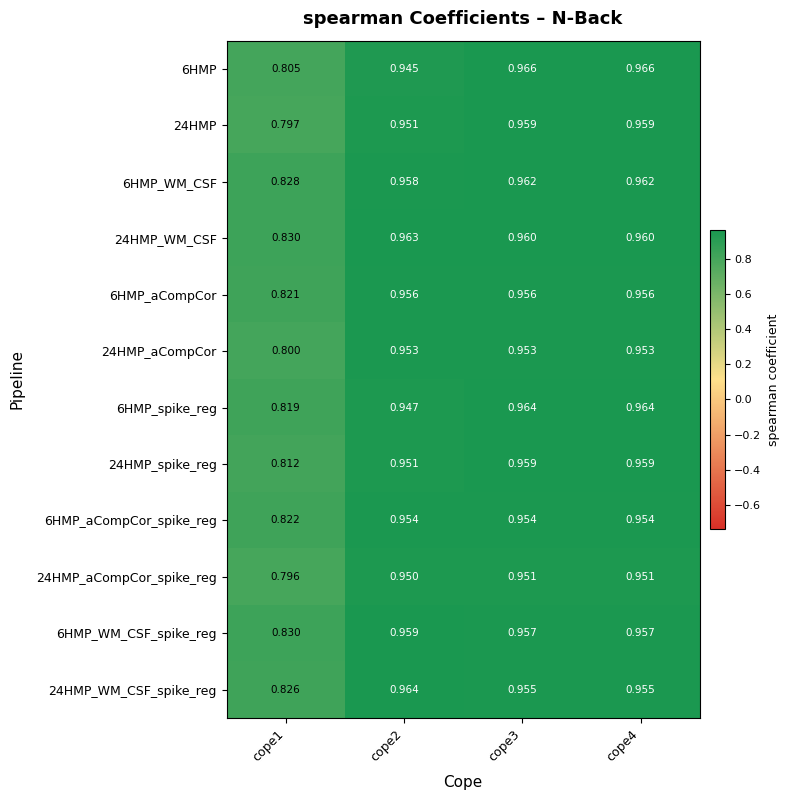

Saved → /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_figures_masked/spearman_heatmap_nback.png


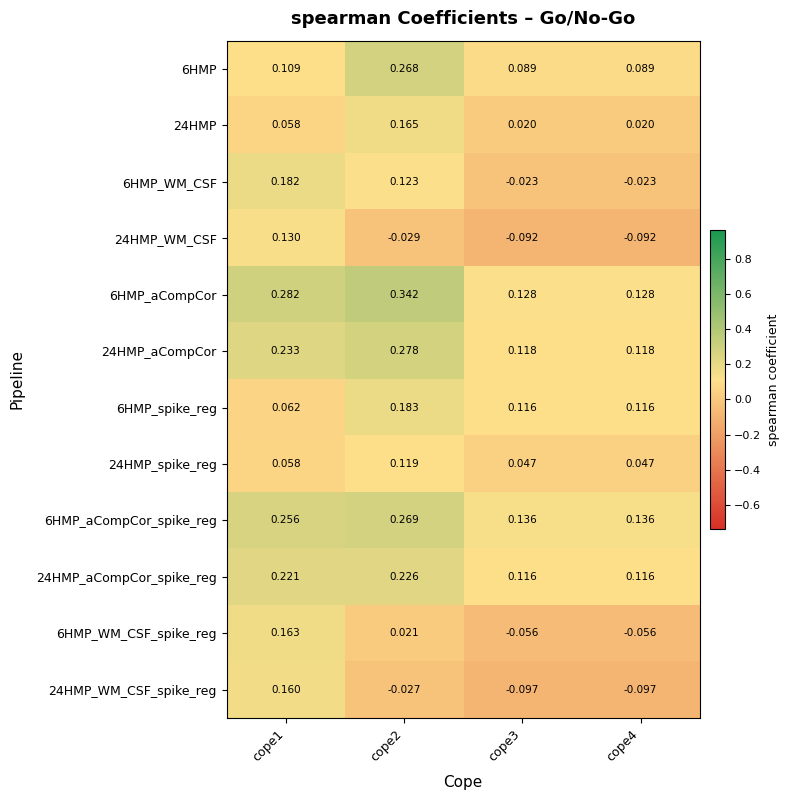

Saved → /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_figures_masked/spearman_heatmap_gonogo.png


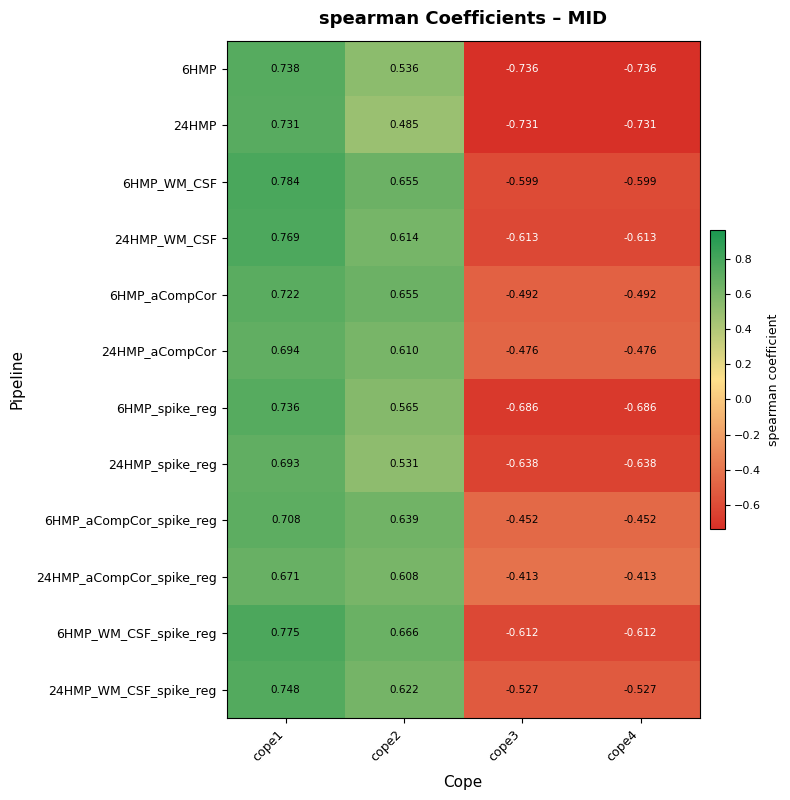

Saved → /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_figures_masked/spearman_heatmap_mid.png


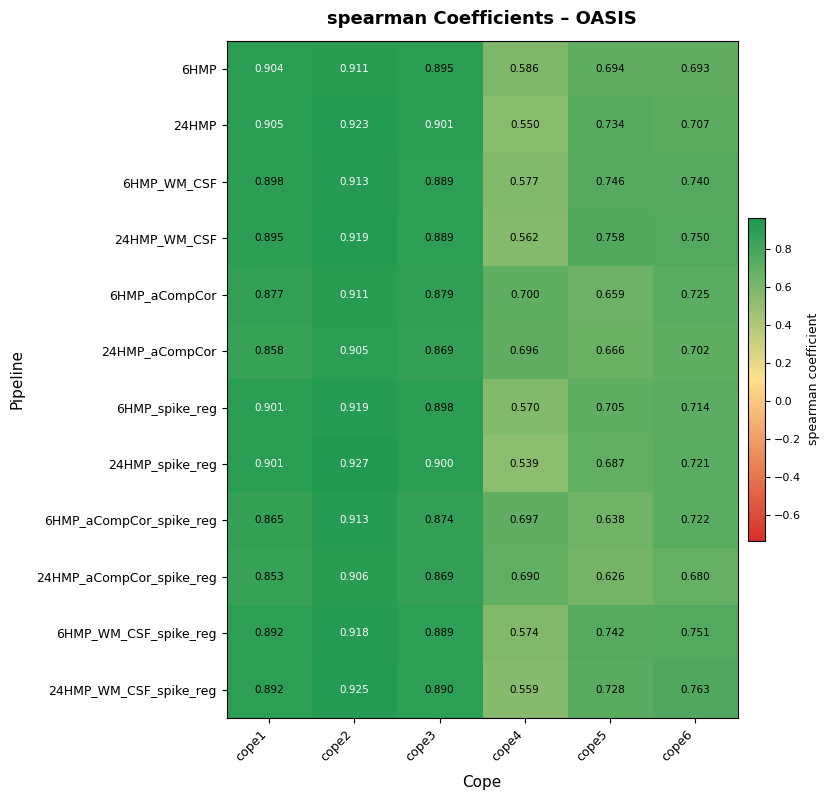

Saved → /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_figures_masked/spearman_heatmap_oasis.png


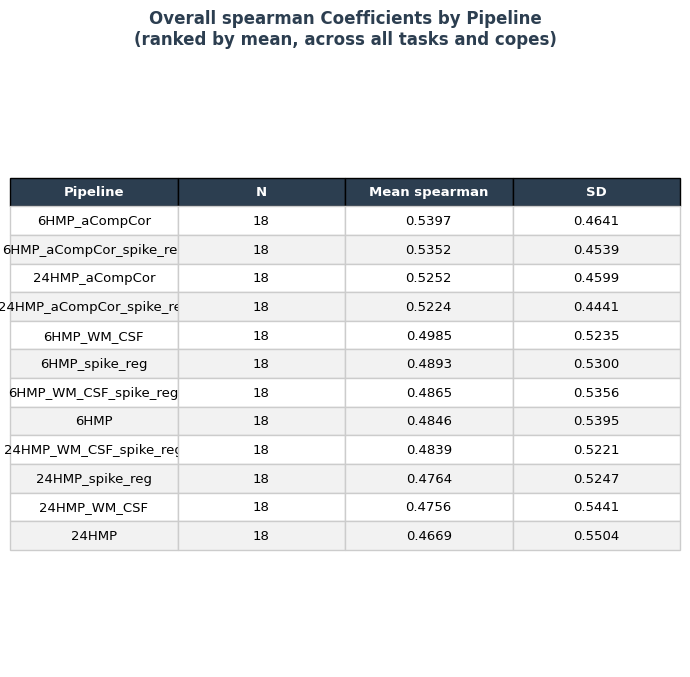

Saved → /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_figures_masked/spearman_table_overall.png


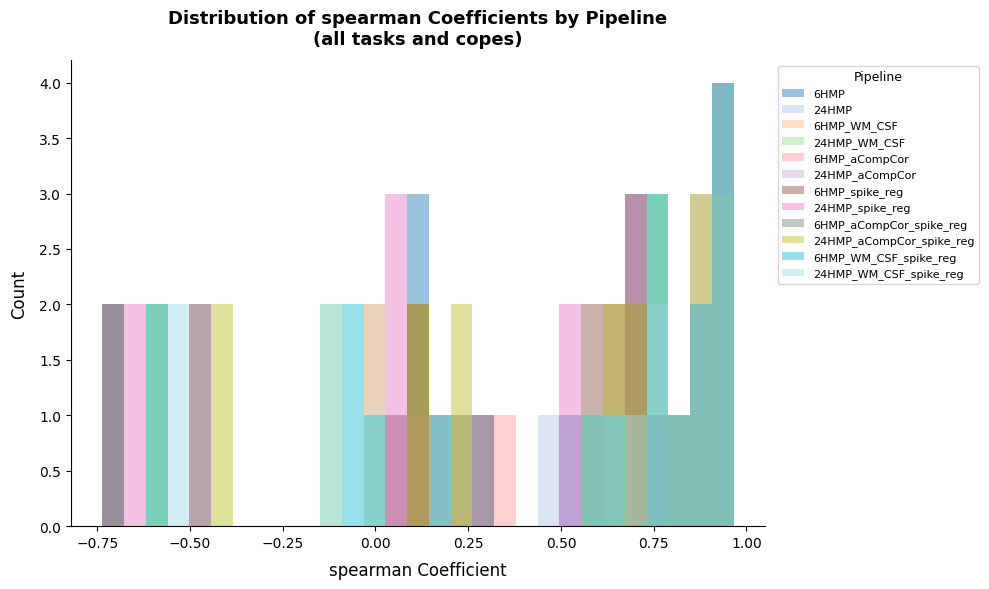

Saved → /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_figures_masked/spearman_histogram_pipelines.png

All figures saved to: /rds/general/project/task_reliability_study/live/MultiverseReliability/group_levels/spearman_figures_masked


In [ ]:
#!/usr/bin/env python3
"""
spearman Coefficient Figures for Thesis
- Per-task: heatmap (pipelines x copes)
- Overall:  clean mean/SD table  +  layered histogram across 12 pipelines
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
import os

# ── CONFIGURATION ──────────────────────────────────────────────────────────────
BASE_DIR    = "/path/to/project/group_levels/spearman_masked"
SUMMARY_DIR = "/path/to/project/group_levels/spearman_summaries_masked"
FIGURE_DIR  = "/path/to/project/group_levels/spearman_figures_masked"
os.makedirs(FIGURE_DIR, exist_ok=True)

TASKS = ["nback", "gonogo", "mid", "oasis"]
TASK_LABELS = {"nback": "N-Back", "gonogo": "Go/No-Go", "mid": "MID", "oasis": "OASIS"}

PIPELINES = [
    "6HMP", "24HMP",
    "6HMP_WM_CSF", "24HMP_WM_CSF",
    "6HMP_aCompCor", "24HMP_aCompCor",
    "6HMP_spike_reg", "24HMP_spike_reg",
    "6HMP_aCompCor_spike_reg", "24HMP_aCompCor_spike_reg",
    "6HMP_WM_CSF_spike_reg", "24HMP_WM_CSF_spike_reg",
]

CMAP = LinearSegmentedColormap.from_list("spearman_cmap", ["#d73027", "#fee08b", "#1a9850"], N=256)

# One distinct colour per pipeline for the histogram
PIPELINE_COLORS = plt.cm.tab20(np.linspace(0, 1, len(PIPELINES)))


# ── DATA LOADING ───────────────────────────────────────────────────────────────

def read_spearman(fp):
    try:
        v = open(fp).read().strip().replace("Spearman_r: ", "").strip()
        return float(v) if v.upper() != "NA" and v != "" else None
    except Exception:
        return None


def load_data():
    csv_path = Path(SUMMARY_DIR) / "all_spearman_values.csv"
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        print(f"Loaded {len(df):,} rows from {csv_path}")
        return df

    print("CSV not found – reading raw spearman txt files ...")
    rows = []
    for task in TASKS:
        task_dir = Path(BASE_DIR) / task
        if not task_dir.exists():
            continue
        for pipeline in PIPELINES:
            pipe_dir = task_dir / pipeline
            if not pipe_dir.exists():
                continue
            for cope_dir in sorted(pipe_dir.glob("cope*")):
                cope = cope_dir.name
                spearman_file = cope_dir / f"{task}_{cope}_{pipeline}_spearman.txt"
                if not spearman_file.exists():
                    spearman_file = cope_dir / "spearman_result.txt"
                if spearman_file.exists():
                    rows.append(dict(task=task, pipeline=pipeline,
                                     cope=cope, spearman=read_spearman(spearman_file)))
    df = pd.DataFrame(rows)
    print(f"Collected {len(df):,} rows from raw files.")
    return df


# ── FIGURE 1–4: Per-task heatmaps (pipelines × copes) ─────────────────────────

def plot_task_heatmap(df_all, task):
    task_df = df_all[df_all["task"] == task].copy()
    if task_df.empty:
        print(f"No data for {task} – skipping.")
        return

    # Pivot: rows = pipelines, columns = copes
    pivot = task_df.pivot_table(index="pipeline", columns="cope",
                                values="spearman", aggfunc="mean")

    # Keep pipeline order consistent
    pipelines_present = [p for p in PIPELINES if p in pivot.index]
    pivot = pivot.loc[pipelines_present]

    # Sort copes naturally
    copes_sorted = sorted(pivot.columns,
                          key=lambda c: int(c.replace("cope", "")) if c.replace("cope", "").isdigit() else 0)
    pivot = pivot[copes_sorted]

    n_pipes, n_copes = pivot.shape
    fig_w = max(8, n_copes * 0.9 + 3)
    fig_h = max(5, n_pipes * 0.55 + 1.5)

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    vmin = df_all["spearman"].min()
    vmax = df_all["spearman"].max()
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    im = ax.imshow(pivot.values, aspect="auto", cmap=CMAP,
                   norm=norm, interpolation="nearest")

    # Annotate each cell with the spearman value
    for r in range(n_pipes):
        for c in range(n_copes):
            val = pivot.values[r, c]
            if not np.isnan(val):
                rgba = CMAP(norm(val))
                luminance = 0.299*rgba[0] + 0.587*rgba[1] + 0.114*rgba[2]
                txt_color = "black" if luminance > 0.45 else "white"
                ax.text(c, r, f"{val:.3f}", ha="center", va="center",
                        fontsize=7.5, color=txt_color)
            else:
                ax.text(c, r, "NA", ha="center", va="center",
                        fontsize=7.5, color="#888888")

    ax.set_xticks(range(n_copes))
    ax.set_xticklabels(copes_sorted, rotation=45, ha="right", fontsize=9)
    ax.set_yticks(range(n_pipes))
    ax.set_yticklabels(pipelines_present, fontsize=9)
    ax.set_xlabel("Cope", fontsize=11, labelpad=8)
    ax.set_ylabel("Pipeline", fontsize=11, labelpad=8)
    ax.set_title(f"spearman Coefficients – {TASK_LABELS[task]}",
                 fontsize=13, fontweight="bold", pad=12)

    cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label("spearman coefficient", fontsize=9)
    cbar.ax.tick_params(labelsize=8)

    plt.tight_layout()
    out = Path(FIGURE_DIR) / f"spearman_heatmap_{task}.png"
    fig.savefig(out, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()
    print(f"Saved → {out}")


# ── FIGURE 5a: Overall mean/SD table (plain, no colour) ───────────────────────

def plot_overall_table(df_all):
    rows = []
    for pipeline in PIPELINES:
        sub = df_all[df_all["pipeline"] == pipeline]["spearman"].dropna()
        rows.append({
            "Pipeline": pipeline,
            "N": int(len(sub)),
            "Mean": sub.mean()   if len(sub) else np.nan,
            "SD":   sub.std()    if len(sub) else np.nan,
        })

    tbl_df = (pd.DataFrame(rows)
              .sort_values("Mean", ascending=False)
              .reset_index(drop=True))

    # Format for display
    display = tbl_df.copy()
    display["Mean"] = display["Mean"].apply(lambda x: f"{x:.4f}" if pd.notna(x) else "NA")
    display["SD"]   = display["SD"].apply(  lambda x: f"{x:.4f}" if pd.notna(x) else "NA")
    display["N"]    = display["N"].astype(str)

    n_rows = len(display)
    fig, ax = plt.subplots(figsize=(7, 0.42 * (n_rows + 2) + 1))
    ax.axis("off")

    col_labels = ["Pipeline", "N", "Mean spearman", "SD"]
    cell_text  = display[["Pipeline", "N", "Mean", "SD"]].values.tolist()

    tbl = ax.table(cellText=cell_text, colLabels=col_labels,
                   cellLoc="center", loc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9.5)
    tbl.scale(1, 1.5)

    header_color = "#2C3E50"
    alt_color    = "#f2f2f2"

    for col_idx in range(4):
        cell = tbl[0, col_idx]
        cell.set_facecolor(header_color)
        cell.set_text_props(color="white", fontweight="bold")

    for row_idx in range(1, n_rows + 1):
        bg = alt_color if row_idx % 2 == 0 else "white"
        for col_idx in range(4):
            tbl[row_idx, col_idx].set_facecolor(bg)
            tbl[row_idx, col_idx].set_edgecolor("#cccccc")

    ax.set_title("Overall spearman Coefficients by Pipeline\n(ranked by mean, across all tasks and copes)",
                 fontsize=12, fontweight="bold", pad=12, color=header_color)

    plt.tight_layout()
    out = Path(FIGURE_DIR) / "spearman_table_overall.png"
    fig.savefig(out, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()
    print(f"Saved → {out}")

    return tbl_df


# ── FIGURE 5b: Layered histogram across 12 pipelines ──────────────────────────

def plot_layered_histogram(df_all):
    fig, ax = plt.subplots(figsize=(10, 6))

    all_vals = df_all["spearman"].dropna()
    global_min, global_max = all_vals.min(), all_vals.max()
    bins = np.linspace(global_min, global_max, 30)

    for i, pipeline in enumerate(PIPELINES):
        vals = df_all[df_all["pipeline"] == pipeline]["spearman"].dropna()
        if len(vals) == 0:
            continue
        ax.hist(vals, bins=bins, alpha=0.45, label=pipeline,
                color=PIPELINE_COLORS[i], edgecolor="none")

    ax.set_xlabel("spearman Coefficient", fontsize=12, labelpad=8)
    ax.set_ylabel("Count", fontsize=12, labelpad=8)
    ax.set_title("Distribution of spearman Coefficients by Pipeline\n(all tasks and copes)",
                 fontsize=13, fontweight="bold", pad=12)

    ax.legend(title="Pipeline", fontsize=8, title_fontsize=9,
              bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    out = Path(FIGURE_DIR) / "spearman_histogram_pipelines.png"
    fig.savefig(out, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close()
    print(f"Saved → {out}")


# ── MAIN ───────────────────────────────────────────────────────────────────────

def main():
    df_all = load_data()
    print(f"Valid: {df_all['spearman'].notna().sum():,}  |  NA: {df_all['spearman'].isna().sum():,}\n")

    # Heatmaps (one per task)
    for task in TASKS:
        plot_task_heatmap(df_all, task)

    # Overall table + histogram
    plot_overall_table(df_all)
    plot_layered_histogram(df_all)

    print(f"\nAll figures saved to: {FIGURE_DIR}")


if __name__ == "__main__":
    main()